In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
external = pd.read_csv("external_sources.csv")

print("Dataset shape:", external.shape)

external.head()

Dataset shape: (12999, 20)


,uuid,ord_in_thread,author,published,title,text,language,crawled,site_url,country,domain_rank,thread_title,spam_score,main_img_url,replies_count,participants_count,likes,comments,shares,type
0,6a175f46bcd24d39b3e962ad0f29936721db70db,0,Barracuda Brigade,2016-10-26T21:41:00.000+03:00,Muslims BUSTED: They Stole Millions In Gov’t B...,Print They should pay all the back all the mon...,english,2016-10-27T01:49:27.168+03:00,100percentfedup.com,US,25689.0,Muslims BUSTED: They Stole Millions In Gov’t B...,0.000,http://bb4sp.com/wp-content/uploads/2016/10/Fu...,0,1,0,0,0,bias
1,2bdc29d12605ef9cf3f09f9875040a7113be5d5b,0,reasoning with facts,2016-10-29T08:47:11.259+03:00,Re: Why Did Attorney General Loretta Lynch Ple...,Why Did Attorney General Loretta Lynch Plead T...,english,2016-10-29T08:47:11.259+03:00,100percentfedup.com,US,25689.0,Re: Why Did Attorney General Loretta Lynch Ple...,0.000,http://bb4sp.com/wp-content/uploads/2016/10/Fu...,0,1,0,0,0,bias
2,c70e149fdd53de5e61c29281100b9de0ed268bc3,0,Barracuda Brigade,2016-10-31T01:41:49.479+02:00,BREAKING: Weiner Cooperating With FBI On Hilla...,Red State : \nFox News Sunday reported this mo...,english,2016-10-31T01:41:49.479+02:00,100percentfedup.com,US,25689.0,BREAKING: Weiner Cooperating With FBI On Hilla...,0.000,http://bb4sp.com/wp-content/uploads/2016/10/Fu...,0,1,0,0,0,bias
3,7cf7c15731ac2a116dd7f629bd57ea468ed70284,0,Fed Up,2016-11-01T05:22:00.000+02:00,PIN DROP SPEECH BY FATHER OF DAUGHTER Kidnappe...,Email Kayla Mueller was a prisoner and torture...,english,2016-11-01T15:46:26.304+02:00,100percentfedup.com,US,25689.0,PIN DROP SPEECH BY FATHER OF DAUGHTER Kidnappe...,0.068,http://100percentfedup.com/wp-content/uploads/...,0,0,0,0,0,bias
4,0206b54719c7e241ffe0ad4315b808290dbe6c0f,0,Fed Up,2016-11-01T21:56:00.000+02:00,FANTASTIC! TRUMP'S 7 POINT PLAN To Reform Heal...,Email HEALTHCARE REFORM TO MAKE AMERICA GREAT ...,english,2016-11-01T23:59:42.266+02:00,100percentfedup.com,US,25689.0,FANTASTIC! TRUMP'S 7 POINT PLAN To Reform Heal...,0.865,http://100percentfedup.com/wp-content/uploads/...,0,0,0,0,0,bias


In [3]:
sources = external[
    ["site_url", "type", "domain_rank", "spam_score"]
].copy()

sources.head()

,site_url,type,domain_rank,spam_score
0,100percentfedup.com,bias,25689.0,0.000
1,100percentfedup.com,bias,25689.0,0.000
2,100percentfedup.com,bias,25689.0,0.000
3,100percentfedup.com,bias,25689.0,0.068
4,100percentfedup.com,bias,25689.0,0.865


In [4]:
# Clean the domain names
sources["Domain"] = (
    sources["site_url"]
    .fillna("")
    .str.lower()
    .str.replace(r"^https?://", "", regex=True)
    .str.replace(r"^www\.", "", regex=True)
    .str.split("/")
    .str[0]
)

sources = sources[sources["Domain"] != ""]

sources[["Domain", "type", "domain_rank", "spam_score"]].head()

,Domain,type,domain_rank,spam_score
0,100percentfedup.com,bias,25689.0,0.000
1,100percentfedup.com,bias,25689.0,0.000
2,100percentfedup.com,bias,25689.0,0.000
3,100percentfedup.com,bias,25689.0,0.068
4,100percentfedup.com,bias,25689.0,0.865


In [5]:
sources["type"].value_counts()

type
bs            11492
bias            443
conspiracy      430
hate            246
satire          146
state           121
junksci         102
fake             19
Name: count, dtype: int64

In [6]:
# Identify frequently appearing news sources
domain_frequency = sources["Domain"].value_counts()

domain_frequency.head(15)

Domain
zerohedge.com                     100
disclose.tv                       100
greanvillepost.com                100
govtslaves.info                   100
rinf.com                          100
godlikeproductions.com            100
rt.com                            100
russia-insider.com                100
galacticconnection.com            100
frontpagemag.com                  100
fromthetrenchesworldreport.com    100
freedomoutpost.com                100
shiftfrequency.com                100
shtfplan.com                      100
silverdoctors.com                 100
Name: count, dtype: int64

In [7]:
# Analyse classifications by domain
domain_analysis = sources.groupby("Domain").agg(
    Total_Records=("Domain", "size"),
    Source_Categories=("type", "nunique"),
    Average_Domain_Rank=("domain_rank", "mean"),
    Average_Spam_Score=("spam_score", "mean")
).round(2)

domain_analysis = domain_analysis.sort_values(
    "Total_Records", ascending=False
)

domain_analysis.head(15)

,Total_Records,Source_Categories,Average_Domain_Rank,Average_Spam_Score
Domain,,,,
zerohedge.com,100,1,2435.0,0.00
disclose.tv,100,1,25709.0,0.00
greanvillepost.com,100,1,NaN,0.00
govtslaves.info,100,1,NaN,0.01
rinf.com,100,1,NaN,0.00
godlikeproductions.com,100,1,12387.0,0.00
rt.com,100,1,538.0,0.18
russia-insider.com,100,1,31016.0,0.00
galacticconnection.com,100,1,NaN,0.00


In [8]:
# Compare source categories across domains
category_comparison = sources.groupby(
    ["Domain", "type"]
).size().unstack(fill_value=0)

category_comparison.head(15)

type,bias,bs,conspiracy,fake,hate,junksci,satire,state
Domain,,,,,,,,
100percentfedup.com,33,0,0,0,0,0,0,0
21stcenturywire.com,0,0,24,0,0,0,0,0
abcnews.com.co,0,0,0,2,0,0,0,0
abeldanger.net,0,100,0,0,0,0,0,0
abovetopsecret.com,0,100,0,0,0,0,0,0
activistpost.com,0,0,100,0,0,0,0,0
addictinginfo.org,20,0,0,0,0,0,0,0
adobochronicles.com,0,0,0,13,0,0,0,0
ahtribune.com,0,100,0,0,0,0,0,0


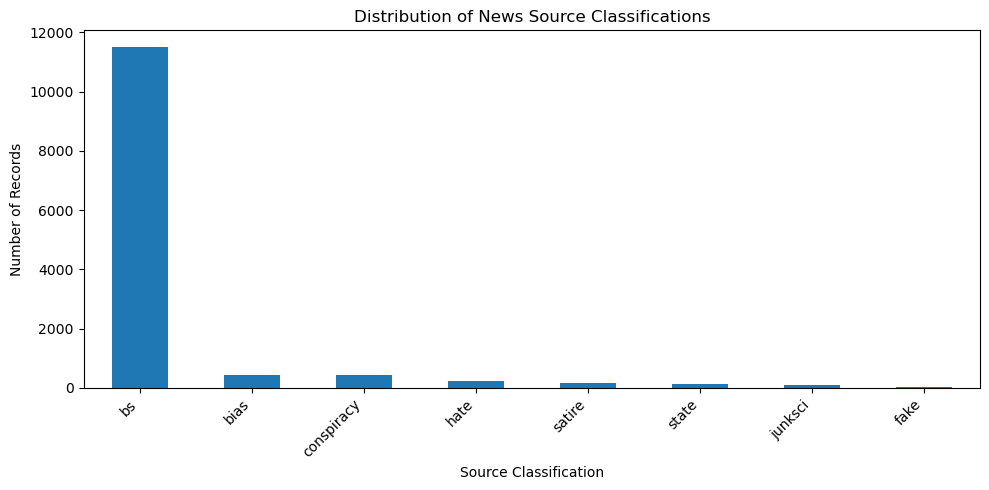

In [9]:
sources["type"].value_counts().plot(kind="bar", figsize=(10, 5))

plt.title("Distribution of News Source Classifications")
plt.xlabel("Source Classification")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [10]:
# Examine domain rank and spam score
sources[["domain_rank", "spam_score"]].describe().round(2)

,domain_rank,spam_score
count,8776.00,12999.00
mean,38093.00,0.03
std,26825.49,0.12
min,486.00,0.00
25%,17423.00,0.00
50%,34478.00,0.00
75%,60570.00,0.00
max,98679.00,1.00


In [11]:
# Identify domains for further investigation
investigation_list = domain_analysis[
    (domain_analysis["Total_Records"] >= 2) &
    (domain_analysis["Source_Categories"] >= 1)
].sort_values(
    "Total_Records", ascending=False
)

investigation_list.head(15)

,Total_Records,Source_Categories,Average_Domain_Rank,Average_Spam_Score
Domain,,,,
zerohedge.com,100,1,2435.0,0.00
barenakedislam.com,100,1,61606.0,0.01
wearechange.org,100,1,NaN,0.00
waterfordwhispersnews.com,100,1,58305.0,0.00
washingtonsblog.com,100,1,64783.0,0.00
amren.com,100,1,94243.0,0.00
amtvmedia.com,100,1,NaN,0.00
worldtruth.tv,100,1,35234.0,0.00
voltairenet.org,100,1,48413.0,0.09
